# 03 – Huấn luyện và baseline


In [1]:
# Colab: Runtime > Change runtime type > GPU (T4)
from google.colab import drive
drive.mount('/content/drive')
import sys
PROJECT = "/content/drive/MyDrive/FER2013_PyTorch"
sys.path.insert(0, PROJECT)
from common import *
print("Device:", DEV, "| torch", torch.__version__)

Mounted at /content/drive
Device: cuda | torch 2.14.1+cu130


## 3.1 Ghi module `train_lib.py`
`run_experiment(tên, **thay_đổi)` lưu `config.json`, `history.csv`, `best.pt`, `curves.png`, `confusion_matrix.png`, `results.json` vào `runs/<tên>/` trên Drive.

In [2]:
%%writefile /content/drive/MyDrive/FER2013_PyTorch/train_lib.py
"""Huấn luyện + đánh giá (Huy – 3123580016)."""
from common import *
from data import *
from models import *

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval(); tot, preds, tgts = 0.0, [], []
    for x, y in loader:
        x, y = x.to(DEV), y.to(DEV); out = model(x)
        tot += criterion(out, y).item() * len(y)
        preds.append(out.argmax(1).cpu()); tgts.append(y.cpu())
    p, t = torch.cat(preds).numpy(), torch.cat(tgts).numpy()
    return tot / len(t), float((p == t).mean()), p, t

def plot_history(hist, path=None):
    ep = [h["epoch"] for h in hist]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for a, (k, t) in zip(ax, [("acc", "Accuracy"), ("loss", "Loss")]):
        a.plot(ep, [h["train_" + k] for h in hist], label="train"); a.plot(ep, [h["val_" + k] for h in hist], label="valid")
        a.set(title=t, xlabel="epoch"); a.legend(); a.grid(alpha=.3)
    fig.tight_layout()
    if path: fig.savefig(path, dpi=130)
    plt.show()

def plot_confusion(cm, title, path=None):
    cmn = cm / cm.sum(1, keepdims=True) * 100
    fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=100)
    ax.set(xticks=range(7), yticks=range(7), xticklabels=CLASSES, yticklabels=CLASSES, xlabel="Predicted", ylabel="True", title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i in range(7):
        for j in range(7):
            ax.text(j, i, f"{cmn[i, j]:.0f}", ha="center", va="center", color="white" if cmn[i, j] > 50 else "black", fontsize=9)
    fig.colorbar(im); fig.tight_layout()
    if path: fig.savefig(path, dpi=130)
    plt.show()

DEFAULTS = dict(group="", note="", model="cnn_medium", bn=True, pretrained=True, conv_drop=0.2, fc_drop=0.5,
                img_size=48, aug="basic", optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler="plateau",
                batch_size=64, epochs=60, patience=12, class_weight=False, label_smoothing=0.0,
                amp=True, workers=2, seed=42)

def make_optimizer(c, params):
    if c["optimizer"] == "adam":  return torch.optim.Adam(params, lr=c["lr"], weight_decay=c["weight_decay"])
    if c["optimizer"] == "adamw": return torch.optim.AdamW(params, lr=c["lr"], weight_decay=c["weight_decay"])
    return torch.optim.SGD(params, lr=c["lr"], momentum=0.9, nesterov=True, weight_decay=c["weight_decay"])

def run_experiment(exp_name, show=True, **override):
    """Chạy 1 thí nghiệm; ghi vào RUNS_DIR/exp_name. Chọn checkpoint theo val_acc, báo cáo test."""
    c = {**DEFAULTS, **override, "exp_name": exp_name}
    set_seed(c["seed"]); out = RUNS_DIR / exp_name; out.mkdir(parents=True, exist_ok=True)
    (out / "config.json").write_text(json.dumps(c, indent=2, ensure_ascii=False))
    loaders, counts, (mean, std) = make_loaders(c["batch_size"], c["aug"], c["img_size"], c["workers"])
    model = build_model(c["model"], c["img_size"], c["bn"], c["conv_drop"], c["fc_drop"], c["pretrained"]).to(DEV)
    n_params = count_params(model); print(f"[{exp_name}] {c['model']} params={n_params:,}")
    w = None
    if c["class_weight"]:
        w = torch.tensor(counts.sum() / (7 * counts), dtype=torch.float32, device=DEV); w = w / w.mean()
    train_crit = nn.CrossEntropyLoss(weight=w, label_smoothing=c["label_smoothing"]); eval_crit = nn.CrossEntropyLoss()
    opt = make_optimizer(c, model.parameters()); sched = None
    if c["scheduler"] == "plateau": sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    elif c["scheduler"] == "cosine": sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=c["epochs"])
    use_amp = c["amp"] and DEV.type == "cuda"; scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    hist, best, bad, t0 = [], None, 0, time.time()
    for ep in range(1, c["epochs"] + 1):
        model.train(); ls, corr, n = 0.0, 0, 0
        for x, y in loaders["train"]:
            x, y = x.to(DEV), y.to(DEV); opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEV.type, enabled=use_amp):
                o = model(x); loss = train_crit(o, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            ls += loss.item() * len(y); corr += (o.argmax(1) == y).sum().item(); n += len(y)
        vl, va, _, _ = evaluate(model, loaders["valid"], eval_crit)
        if sched is not None:
            if c["scheduler"] == "plateau": sched.step(vl)
            else: sched.step()
        rec = dict(epoch=ep, train_loss=ls / n, train_acc=corr / n, val_loss=vl, val_acc=va, lr=opt.param_groups[0]["lr"])
        hist.append(rec)
        print(f"ep {ep:3d} | train {rec['train_loss']:.3f}/{rec['train_acc']:.3f} | val {vl:.3f}/{va:.3f} | lr {rec['lr']:.1e}")
        if best is None or va > best["val_acc"]:
            best, bad = rec, 0
            torch.save({"state_dict": model.state_dict(), "cfg": c, "mean": mean, "std": std}, out / "best.pt")
        else:
            bad += 1
            if bad >= c["patience"]: print(f"Early stopping tại epoch {ep}"); break
    with open(out / "history.csv", "w", newline="") as f:
        wr = csv.DictWriter(f, fieldnames=list(hist[0])); wr.writeheader(); wr.writerows(hist)
    if show: plot_history(hist, out / "curves.png")
    model.load_state_dict(torch.load(out / "best.pt", map_location=DEV)["state_dict"])
    vl, va, _, _ = evaluate(model, loaders["valid"], eval_crit)
    tl, ta, pred, tgt = evaluate(model, loaders["test"], eval_crit)
    cm = confusion_matrix(tgt, pred, labels=range(7))
    if show: plot_confusion(cm, f"{exp_name} - test acc {ta*100:.2f}%", out / "confusion_matrix.png")
    res = dict(exp_name=exp_name, group=c["group"], note=c["note"], model=c["model"], bn=c["bn"], optimizer=c["optimizer"],
               lr=c["lr"], batch_size=c["batch_size"], aug=c["aug"], conv_drop=c["conv_drop"], fc_drop=c["fc_drop"],
               class_weight=c["class_weight"], label_smoothing=c["label_smoothing"], scheduler=c["scheduler"],
               img_size=c["img_size"], params=n_params, best_epoch=best["epoch"], epochs_run=len(hist),
               train_acc_at_best=best["train_acc"], val_acc=va, val_loss=vl, test_acc=ta, test_loss=tl,
               test_macro_f1=float(f1_score(tgt, pred, average="macro")),
               per_class_recall=dict(zip(CLASSES, (cm.diagonal() / cm.sum(1)).tolist())),
               train_time_sec=round(time.time() - t0, 1))
    (out / "results.json").write_text(json.dumps(res, indent=2, ensure_ascii=False))
    print(f"[{exp_name}] val_acc={va:.4f} test_acc={ta:.4f} macroF1={res['test_macro_f1']:.4f}")
    return res

Writing /content/drive/MyDrive/FER2013_PyTorch/train_lib.py


## 3.2 Chạy thử nhanh (2 epoch)

In [3]:
from train_lib import *
_ = run_experiment('smoke', epochs=2, patience=2, show=False)
import shutil; shutil.rmtree(RUNS_DIR/'smoke')  # xóa kết quả chạy thử

[smoke] cnn_medium params=12,103,623


/content/drive/MyDrive/FER2013_PyTorch/train_lib.py:63: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  use_amp = c["amp"] and DEV.type == "cuda"; scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


ep   1 | train 2.026/0.237 | val 1.796/0.249 | lr 1.0e-03
ep   2 | train 1.771/0.268 | val 1.724/0.324 | lr 1.0e-03
[smoke] val_acc=0.3243 test_acc=0.3188 macroF1=0.1763


## 3.3 Baseline đầy đủ

[base] cnn_medium params=12,103,623


/content/drive/MyDrive/FER2013_PyTorch/train_lib.py:63: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  use_amp = c["amp"] and DEV.type == "cuda"; scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


ep   1 | train 2.026/0.237 | val 1.796/0.249 | lr 1.0e-03
ep   2 | train 1.771/0.268 | val 1.724/0.324 | lr 1.0e-03
ep   3 | train 1.612/0.356 | val 1.522/0.407 | lr 1.0e-03
ep   4 | train 1.492/0.414 | val 1.394/0.463 | lr 1.0e-03
ep   5 | train 1.420/0.455 | val 1.315/0.494 | lr 1.0e-03
ep   6 | train 1.355/0.478 | val 1.300/0.489 | lr 1.0e-03
ep   7 | train 1.308/0.501 | val 1.239/0.523 | lr 1.0e-03
ep   8 | train 1.266/0.517 | val 1.194/0.540 | lr 1.0e-03
ep   9 | train 1.230/0.535 | val 1.207/0.542 | lr 1.0e-03
ep  10 | train 1.200/0.545 | val 1.117/0.571 | lr 1.0e-03
ep  11 | train 1.177/0.557 | val 1.136/0.559 | lr 1.0e-03
ep  12 | train 1.146/0.570 | val 1.082/0.582 | lr 1.0e-03
ep  13 | train 1.119/0.583 | val 1.072/0.588 | lr 1.0e-03
ep  14 | train 1.104/0.585 | val 1.076/0.588 | lr 1.0e-03
ep  15 | train 1.086/0.594 | val 1.101/0.582 | lr 1.0e-03
ep  16 | train 1.067/0.600 | val 1.070/0.605 | lr 1.0e-03
ep  17 | train 1.055/0.603 | val 1.050/0.597 | lr 1.0e-03
ep  18 | train

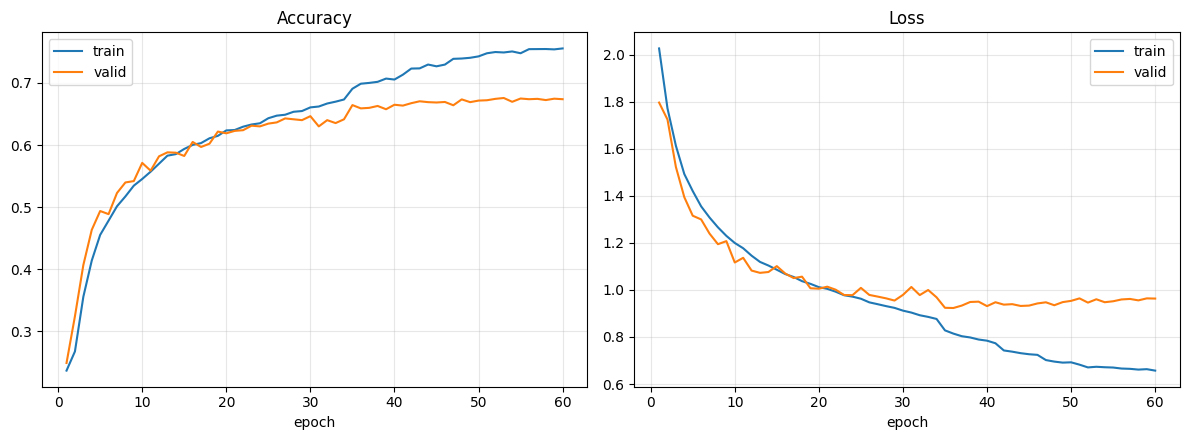

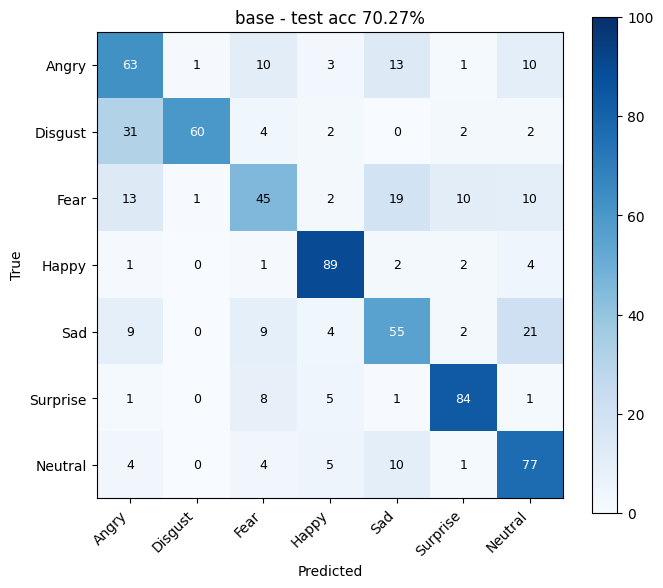

[base] val_acc=0.6757 test_acc=0.7027 macroF1=0.6810


In [4]:
base = run_experiment('base', group='BASE', note='baseline')